# Notebook 1: Descarga y limpieza de precios con yfinance

**Proyecto:** “¿Qué habría pasado con 100 € al mes?” Una guía con datos para el pequeño inversor en España

**Autores:** Yassine y Adriana

**Activos (desde 2010):** S&P 500, IBEX 35, oro, bitcoin, Nvidia y cambio euro-dólar

## 1. Instalación de yfinance

In [7]:
%pip install yfinance


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Importar librerías

In [8]:
import yfinance as yf      
import pandas as pd        
import os      

## 3. Definir los 6 activos y el periodo de estudio (2010 – hoy)

In [9]:

activos = {
    "^GSPC":    "sp500",      # S&P 500 (en dólares)
    "^IBEX":    "ibex35",     # IBEX 35 (en euros)
   "4GLD.DE":  "oro",        # oro, ETC Xetra-Gold (ya en euros)
    "BTC-EUR":  "bitcoin",    # bitcoin (ya en euros)
    "NVDA":     "nvidia",     # Nvidia (en dólares)
    "EURUSD=X": "eur_usd",    # cuántos dólares vale 1 euro
}

## 4. Descargar los precios mensuales

In [10]:
datos = yf.download(
    tickers=list(activos.keys()),   # los códigos del diccionario
    start="2010-01-01",             # desde enero de 2010
    interval="1mo",                 # un dato por mes
    auto_adjust=True,               # corrige los precios si una acción se ha dividido (split)
)

[*********************100%***********************]  6 of 6 completed


## 5. Comprobar que cada activo tiene datos mensuales suficientes

Fecha de inicio real de cada serie (bitcoin empieza en 2014)

In [11]:
precios = datos["Close"]                 # de todo lo descargado, solo el precio de cierre
precios = precios.rename(columns=activos)  # cambiamos "^GSPC" por "sp500", etc.
precios.index.name = "fecha"             # ponemos nombre a la columna de fechas
precios.head()
precios.columns.name = None

In [12]:
print(precios.shape)          # cuántas filas (meses) y columnas (activos)
print(precios.isna().sum())   # cuántos huecos (NaN) tiene cada activo

(203, 6)
oro         0
bitcoin    56
eur_usd     0
nvidia      0
sp500       0
ibex35      0
dtype: int64


In [13]:
precios.apply(lambda s: s.first_valid_index())

oro       2010-01-01
bitcoin   2014-09-01
eur_usd   2010-01-01
nvidia    2010-01-01
sp500     2010-01-01
ibex35    2010-01-01
dtype: datetime64[s]

## 6. Limpieza de datos

### 6.1 Valores nulos y meses que faltan

In [14]:
for col in precios.columns:
    inicio = precios[col].first_valid_index()
    fin = precios[col].last_valid_index()
    huecos = precios.loc[inicio:fin, col].isna().sum()
    print(col, "empieza en", inicio.date(), "→ huecos:", huecos)

oro empieza en 2010-01-01 → huecos: 0
bitcoin empieza en 2014-09-01 → huecos: 0
eur_usd empieza en 2010-01-01 → huecos: 0
nvidia empieza en 2010-01-01 → huecos: 0
sp500 empieza en 2010-01-01 → huecos: 0
ibex35 empieza en 2010-01-01 → huecos: 0


### 6.2 Formato de fechas y nombres de columnas

In [15]:
precios.index = pd.to_datetime(precios.index)   # asegurar que el índice son fechas
precios.columns.name = None                     # quitar la palabra "Ticker"

orden = ["sp500", "ibex35", "oro", "bitcoin", "nvidia", "eur_usd"]
precios = precios[orden]                        # columnas en un orden lógico

precios = precios.loc[:"2026-09-01"]            # quitar octubre de 2026 (mes sin terminar)

precios.head()

,sp500,ibex35,oro,bitcoin,nvidia,eur_usd
fecha,,,,,,
2010-01-01,1073.869995,10947.689453,24.930000,NaN,0.351929,1.387694
2010-02-01,1104.489990,10333.588867,26.290001,NaN,0.370451,1.363791
2010-03-01,1169.430054,10871.289062,26.500000,NaN,0.397892,1.350804
2010-04-01,1186.689941,10492.189453,28.600000,NaN,0.359246,1.329805
2010-05-01,1089.410034,9359.390625,31.860001,NaN,0.300477,1.228788


### 6.3 Pasar a euros los precios en dólares

In [16]:
en_dolares = ["sp500", "nvidia"]   # el oro (4GLD.DE) y el bitcoin ya vienen en euros

for col in en_dolares:
    precios[col] = precios[col] / precios["eur_usd"]

precios.head()


,sp500,ibex35,oro,bitcoin,nvidia,eur_usd
fecha,,,,,,
2010-01-01,773.852156,10947.689453,24.930000,NaN,0.253607,1.387694
2010-02-01,809.867281,10333.588867,26.290001,NaN,0.271633,1.363791
2010-03-01,865.729066,10871.289062,26.500000,NaN,0.294559,1.350804
2010-04-01,892.378983,10492.189453,28.600000,NaN,0.270150,1.329805
2010-05-01,886.572800,9359.390625,31.860001,NaN,0.244531,1.228788


## 7. Revisión visual de las series

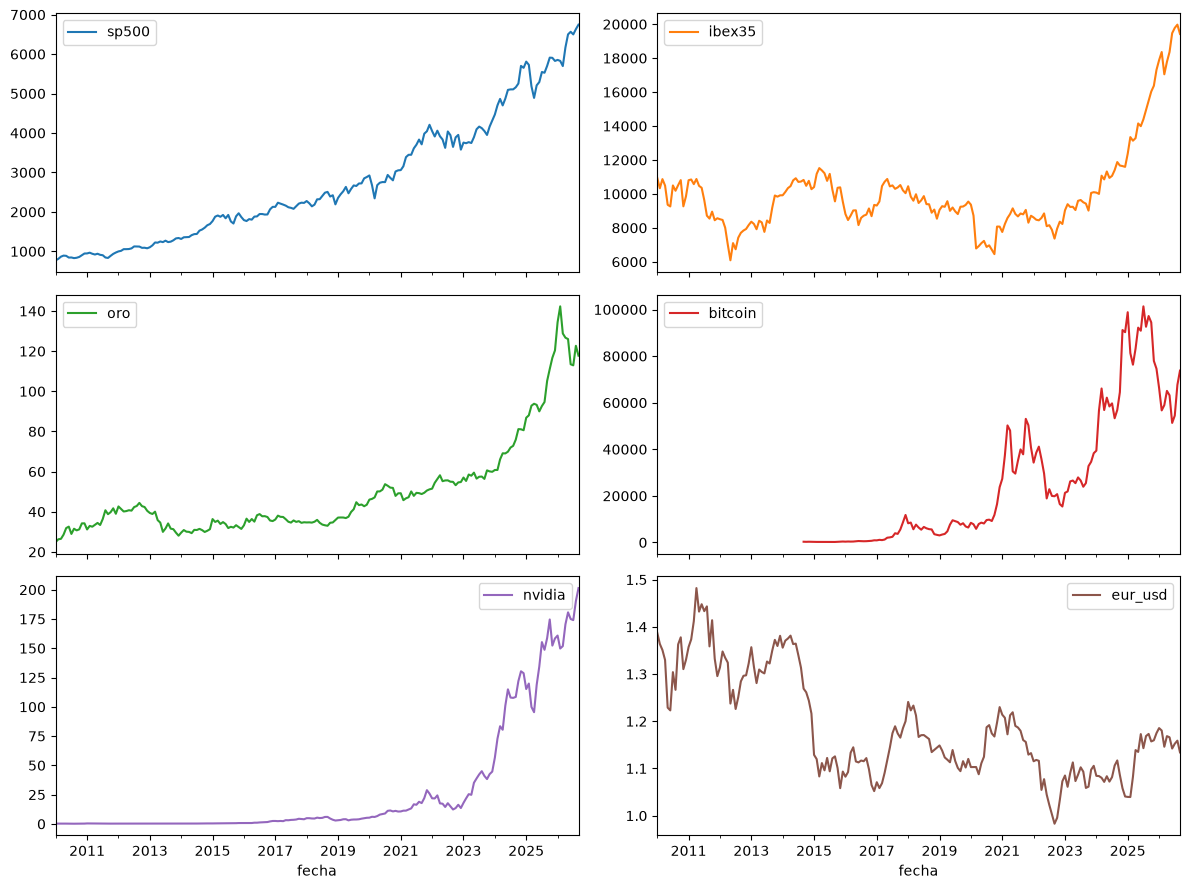

In [17]:
import matplotlib.pyplot as plt

precios.plot(subplots=True, layout=(3, 2), figsize=(12, 9), legend=True)
plt.tight_layout()
plt.show()

## 8. Guardar los precios limpios en CSV

In [18]:
import os
import pandas as pd

In [19]:
os.makedirs("datos", exist_ok=True)                  # crea la carpeta "datos" si no existe
precios.to_csv("datos/precios_mensuales_eur.csv") 

precios_comprobacion = pd.read_csv(
    "datos/precios_mensuales_eur.csv",
    index_col="fecha",
    parse_dates=True
)

precios_comprobacion.head()

# Comprobación: lo volvemos a leer
pd.read_csv("datos/precios_mensuales_eur.csv", index_col="fecha", parse_dates=True).head()


,sp500,ibex35,oro,bitcoin,nvidia,eur_usd
fecha,,,,,,
2010-01-01,773.852156,10947.689453,24.930000,NaN,0.253607,1.387694
2010-02-01,809.867281,10333.588867,26.290001,NaN,0.271633,1.363791
2010-03-01,865.729066,10871.289062,26.500000,NaN,0.294559,1.350804
2010-04-01,892.378983,10492.189453,28.600000,NaN,0.270150,1.329805
2010-05-01,886.572800,9359.390625,31.860001,NaN,0.244531,1.228788


In [20]:
precios.head()

,sp500,ibex35,oro,bitcoin,nvidia,eur_usd
fecha,,,,,,
2010-01-01,773.852156,10947.689453,24.930000,NaN,0.253607,1.387694
2010-02-01,809.867281,10333.588867,26.290001,NaN,0.271633,1.363791
2010-03-01,865.729066,10871.289062,26.500000,NaN,0.294559,1.350804
2010-04-01,892.378983,10492.189453,28.600000,NaN,0.270150,1.329805
2010-05-01,886.572800,9359.390625,31.860001,NaN,0.244531,1.228788


In [21]:
import os

os.makedirs("datos", exist_ok=True)

precios.to_csv("datos/precios_mensuales_eur.csv")

precios_comprobacion = pd.read_csv(
    "datos/precios_mensuales_eur.csv",
    index_col="fecha",
    parse_dates=True
)

precios_comprobacion.head()

,sp500,ibex35,oro,bitcoin,nvidia,eur_usd
fecha,,,,,,
2010-01-01,773.852156,10947.689453,24.930000,NaN,0.253607,1.387694
2010-02-01,809.867281,10333.588867,26.290001,NaN,0.271633,1.363791
2010-03-01,865.729066,10871.289062,26.500000,NaN,0.294559,1.350804
2010-04-01,892.378983,10492.189453,28.600000,NaN,0.270150,1.329805
2010-05-01,886.572800,9359.390625,31.860001,NaN,0.244531,1.228788


- **Archivo generado:** `datos/precios_mensuales_eur.csv`, 201 meses (ene-2010 a sep-2026), todo en euros.
- **Bitcoin** empieza en sep-2014: los meses anteriores están vacíos a propósito (no se podía comprar).
- **Oro:** ETC Xetra-Gold (4GLD.DE), en euros. En Europa se llaman ETC, no ETF.
- **S&P 500 y Nvidia** se pasaron a euros con el cambio EUR/USD de cada mes.
- **Limitación:** el S&P 500 y el IBEX son índices sin dividendos, así que el resultado real de un fondo indexado sería algo mayor.